In [3]:
!pip install -q GEOparse

In [5]:
import pandas as pd, numpy as np, GEOparse

data = pd.read_csv("tnbc_data.csv", index_col=0)
y = data["label"]
X = data.drop(columns="label")
if X.values.max() > 100:
    X = np.log2(X + 1)

gpl = GEOparse.get_GEO("GPL570", destdir="./").table
m = gpl[["ID", "Gene Symbol"]].dropna()
m = m[~m["Gene Symbol"].str.contains("///")]
mapping = dict(zip(m["ID"], m["Gene Symbol"]))

X = X.T
X["gene"] = X.index.map(mapping)
X = X.dropna(subset=["gene"]).groupby("gene").mean().T
print("Ready! X shape:", X.shape, "| y shape:", y.shape)

21-Nov-2026 15:46:29 DEBUG utils - Directory ./ already exists. Skipping.
DEBUG:GEOparse:Directory ./ already exists. Skipping.
21-Nov-2026 15:46:29 INFO GEOparse - Downloading http://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?targ=self&acc=GPL570&form=text&view=full to ./GPL570.txt
INFO:GEOparse:Downloading http://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?targ=self&acc=GPL570&form=text&view=full to ./GPL570.txt
21-Nov-2026 15:46:32 DEBUG downloader - Total size: 0
DEBUG:GEOparse:Total size: 0
21-Nov-2026 15:46:32 DEBUG downloader - md5: None
DEBUG:GEOparse:md5: None
81.7MB [00:03, 23.1MB/s]
21-Nov-2026 15:46:35 DEBUG downloader - Moving /tmp/tmplgl1krm5 to /content/GPL570.txt
DEBUG:GEOparse:Moving /tmp/tmplgl1krm5 to /content/GPL570.txt
21-Nov-2026 15:46:35 DEBUG downloader - Successfully downloaded http://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?targ=self&acc=GPL570&form=text&view=full
DEBUG:GEOparse:Successfully downloaded http://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?targ=self&acc=GPL570&fo

Ready! X shape: (265, 21655) | y shape: (265,)


In [6]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, RocCurveDisplay
import pandas as pd, matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

Train shape: (185, 21655) | Test shape: (80, 21655)


In [7]:
lasso = Pipeline([("sc", StandardScaler()),
                  ("sel", SelectKBest(f_classif, k=500)),
                  ("clf", LogisticRegression(penalty="l1", solver="liblinear",
                                             C=0.1, class_weight="balanced"))])
rf = Pipeline([("sel", SelectKBest(f_classif, k=500)),
               ("clf", RandomForestClassifier(n_estimators=300,
                                              class_weight="balanced", random_state=42))])

cv = StratifiedKFold(5, shuffle=True, random_state=42)
for name, m in [("LASSO", lasso), ("RandomForest", rf)]:
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc")
    print(name, "CV AUC:", s.mean().round(3), "+/-", s.std().round(3))

LASSO CV AUC: 1.0 +/- 0.0
RandomForest CV AUC: 1.0 +/- 0.0



 LASSO test AUC: 1.0
              precision    recall  f1-score   support

    non-TNBC       1.00      1.00      1.00        20
        TNBC       1.00      1.00      1.00        60

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80


 RandomForest test AUC: 1.0
              precision    recall  f1-score   support

    non-TNBC       1.00      1.00      1.00        20
        TNBC       1.00      1.00      1.00        60

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



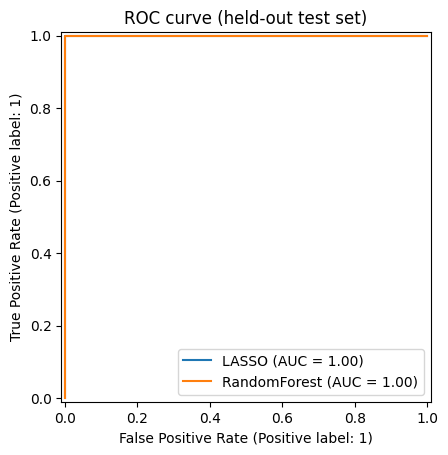

In [8]:
fig, ax = plt.subplots()
for name, m in [("LASSO", lasso), ("RandomForest", rf)]:
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    print("\n", name, "test AUC:", roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]).round(3))
    print(classification_report(y_test, pred, target_names=["non-TNBC", "TNBC"]))
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=ax, name=name)
plt.title("ROC curve (held-out test set)")
plt.savefig("roc_curve.png", dpi=200)
plt.show()

LASSO Test ROC-AUC:         1.0000
Random Forest Test ROC-AUC: 1.0000

=== LASSO Classification Report (Test Set) ===
              precision    recall  f1-score   support

Non-TNBC (0)       1.00      1.00      1.00        20
    TNBC (1)       1.00      1.00      1.00        60

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80

=== Random Forest Classification Report (Test Set) ===
              precision    recall  f1-score   support

Non-TNBC (0)       1.00      1.00      1.00        20
    TNBC (1)       1.00      1.00      1.00        60

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



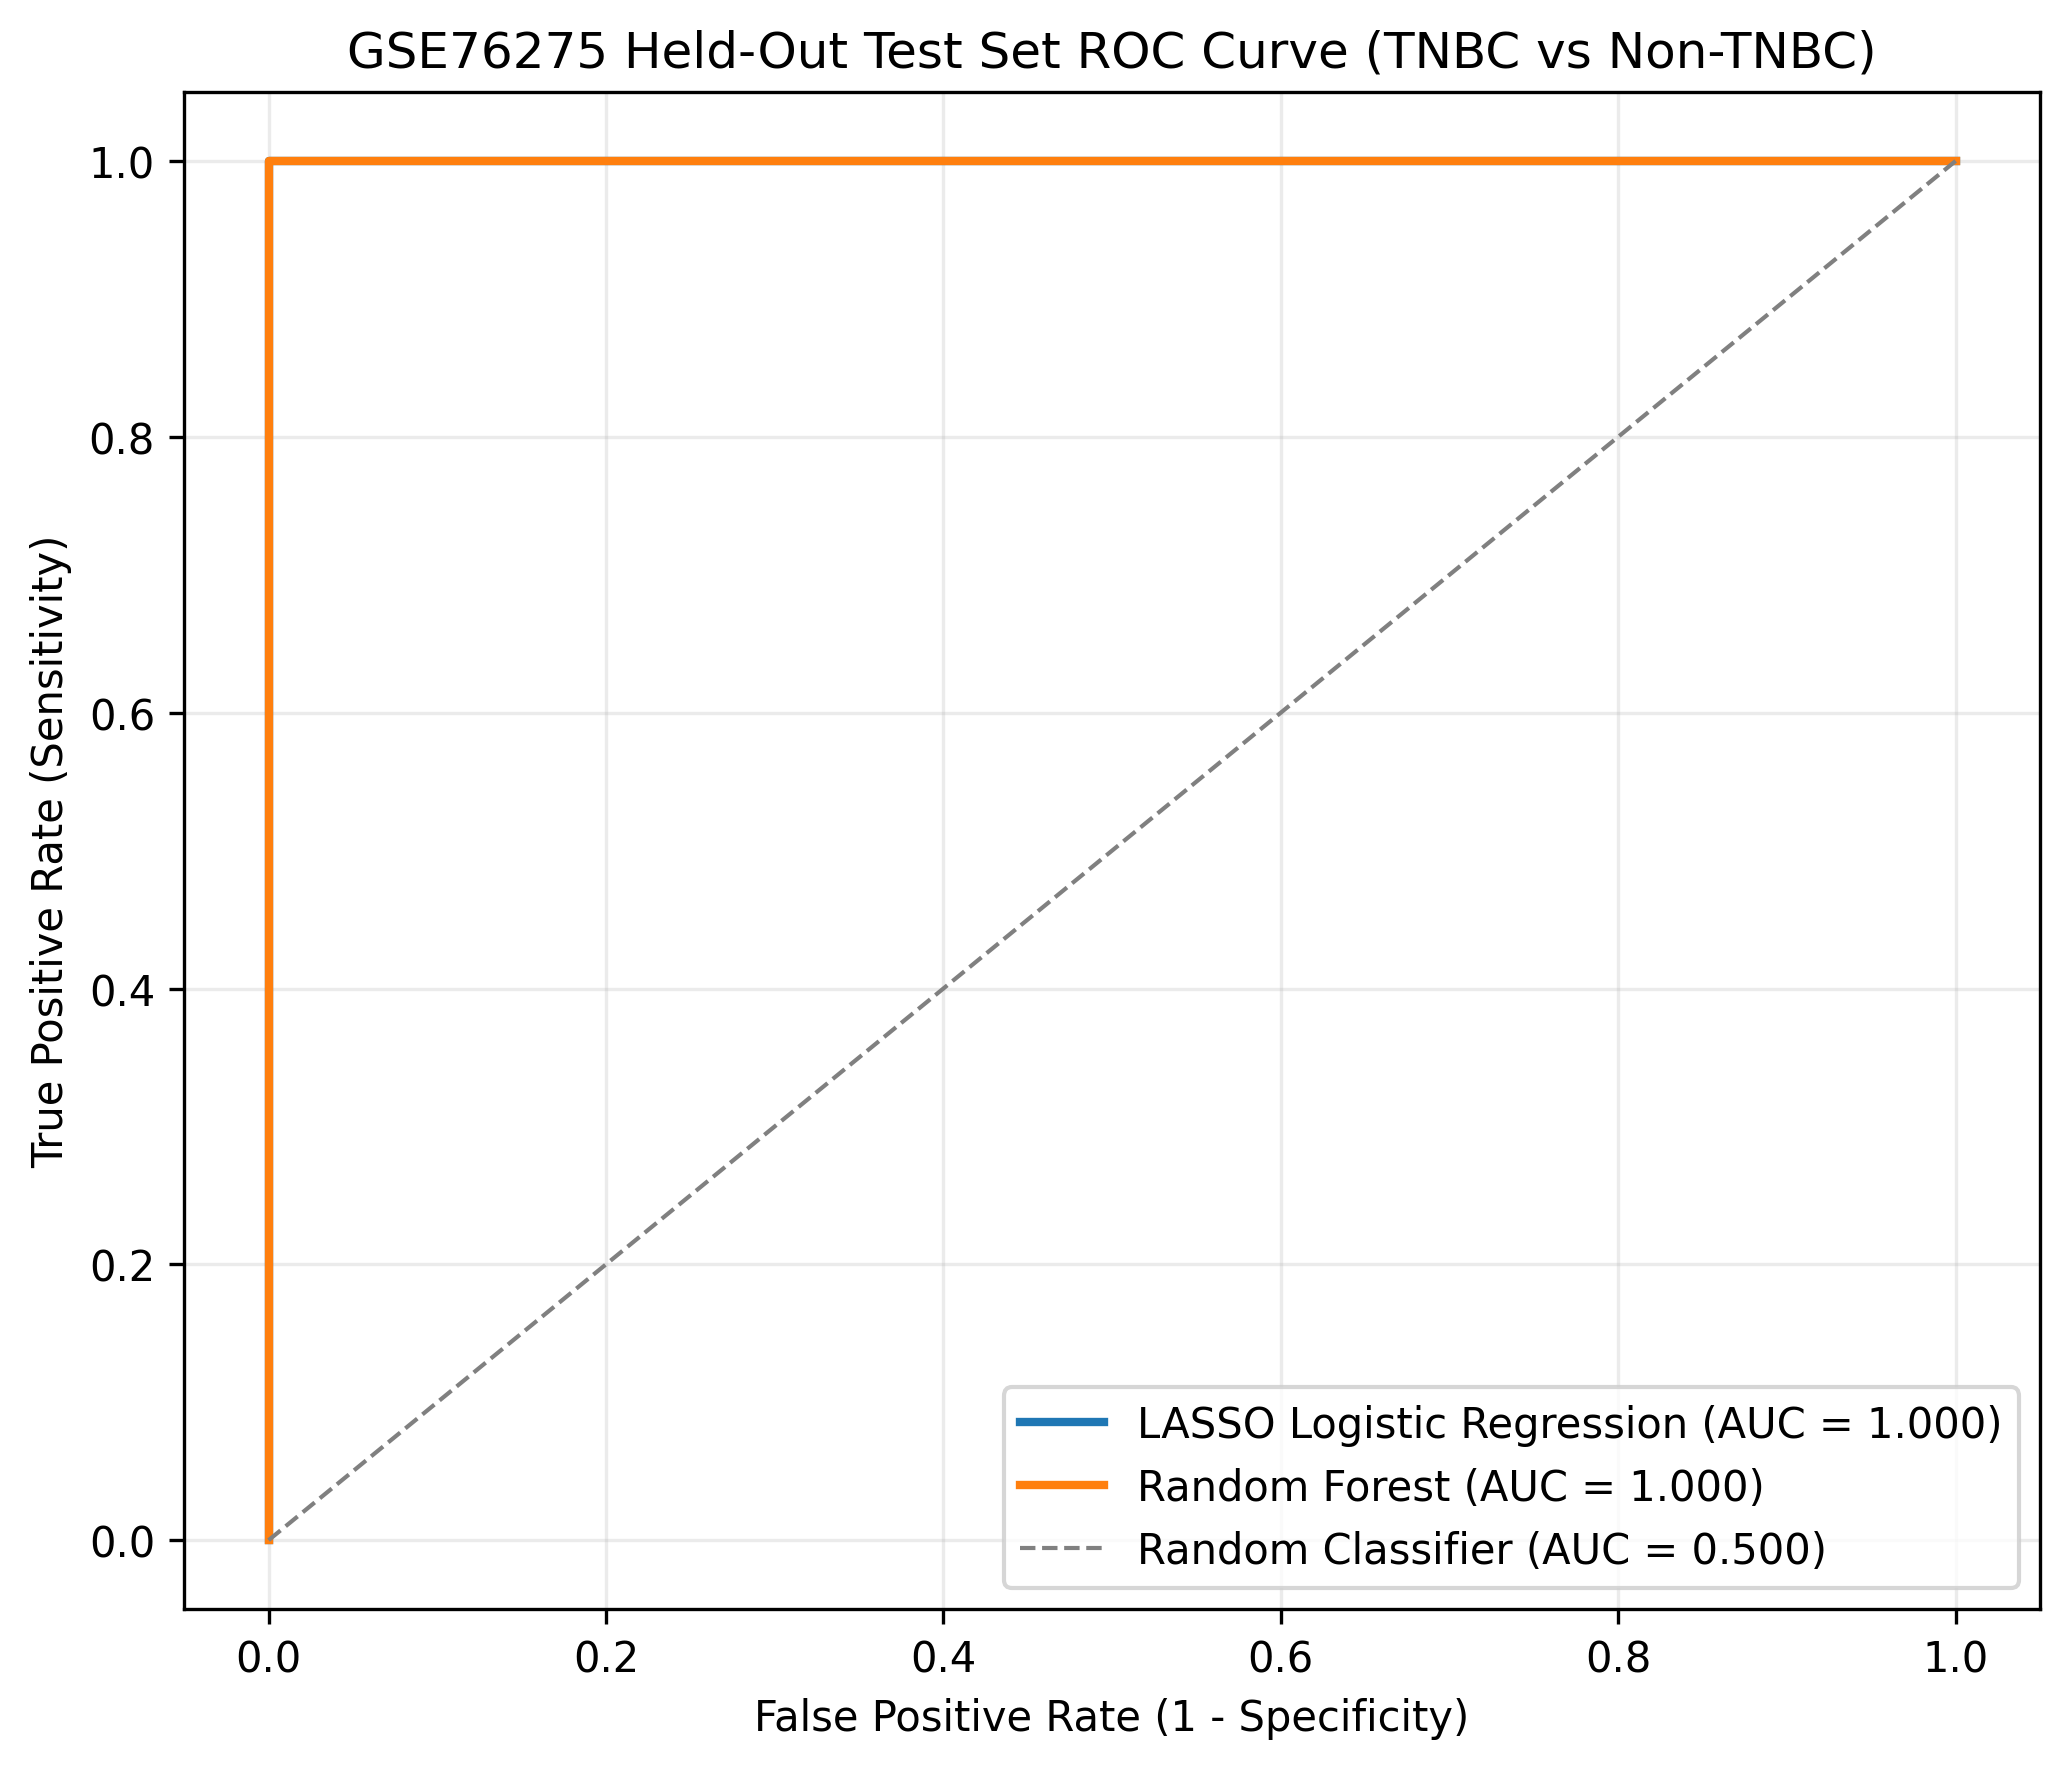

In [9]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)
import matplotlib.pyplot as plt

# 1. Fit both leak-free pipelines on the training split
lasso.fit(X_train, y_train)
rf.fit(X_train, y_train)

# 2. Predict probabilities (for ROC-AUC) and class labels (for classification report)
y_prob_lasso = lasso.predict_proba(X_test)[:, 1]
y_pred_lasso = lasso.predict(X_test)

y_prob_rf = rf.predict_proba(X_test)[:, 1]
y_pred_rf = rf.predict(X_test)

# 3. Print Test ROC-AUC and Classification Reports
print(f"LASSO Test ROC-AUC:         {roc_auc_score(y_test, y_prob_lasso):.4f}")
print(f"Random Forest Test ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}\n")

print("=== LASSO Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred_lasso, target_names=["Non-TNBC (0)", "TNBC (1)"]))

print("=== Random Forest Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred_rf, target_names=["Non-TNBC (0)", "TNBC (1)"]))

# 4. Plot and save ROC Curve
fpr_lasso, tpr_lasso, _ = roc_curve(y_test, y_prob_lasso)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(7, 6), dpi=300)
plt.plot(fpr_lasso, tpr_lasso, lw=2, label=f"LASSO Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lasso):.3f})")
plt.plot(fpr_rf, tpr_rf, lw=2, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1, label="Random Classifier (AUC = 0.500)")

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("GSE76275 Held-Out Test Set ROC Curve (TNBC vs Non-TNBC)")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300)
plt.show()

In [14]:
import numpy as np
import pandas as pd

# 1. Get the 500 genes selected by SelectKBest ('sel')
selected_mask = lasso.named_steps["sel"].get_support()
selected_genes = X.columns[selected_mask]

# 2. Extract L1 Logistic Regression ('clf') coefficients for those 500 genes
coefs = lasso.named_steps["clf"].coef_.ravel()

# 3. Rank non-zero LASSO features by absolute weight
biomarker_df = pd.DataFrame({
    "Gene": selected_genes,
    "LASSO_Coefficient": coefs,
    "Abs_Coefficient": np.abs(coefs),
})

non_zero_df = (
    biomarker_df[biomarker_df["Abs_Coefficient"] > 1e-12]
    .sort_values(by="Abs_Coefficient", ascending=False)
    .reset_index(drop=True)
)

print(f"Total non-zero genes selected by LASSO: {len(non_zero_df)} out of 500")

# 4. Save Top 20 biomarkers to CSV
top20_df = non_zero_df.head(20).copy()
top20_df["Direction_in_TNBC"] = np.where(
    top20_df["LASSO_Coefficient"] > 0,
    "Up-regulated (+)",
    "Down-regulated (-)",
)

top20_df.to_csv("top20_biomarkers.csv", index=False)
print("\nSaved top20_biomarkers.csv. Top biomarkers:")
display(top20_df)

Total non-zero genes selected by LASSO: 6 out of 500

Saved top20_biomarkers.csv. Top biomarkers:


,Gene,LASSO_Coefficient,Abs_Coefficient,Direction_in_TNBC
0,COL18A1-AS1,-1.385933,1.385933,Down-regulated (-)
1,AX746627,-0.704029,0.704029,Down-regulated (-)
2,FZD9,0.260430,0.260430,Up-regulated (+)
3,C5orf49,-0.109788,0.109788,Down-regulated (-)
4,IL5RA,0.088934,0.088934,Up-regulated (+)
5,RP11-55K13.1,-0.049385,0.049385,Down-regulated (-)


LASSO Test ROC-AUC: 1.0
              precision    recall  f1-score   support

Non-TNBC (0)       1.00      1.00      1.00        20
    TNBC (1)       1.00      1.00      1.00        60

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



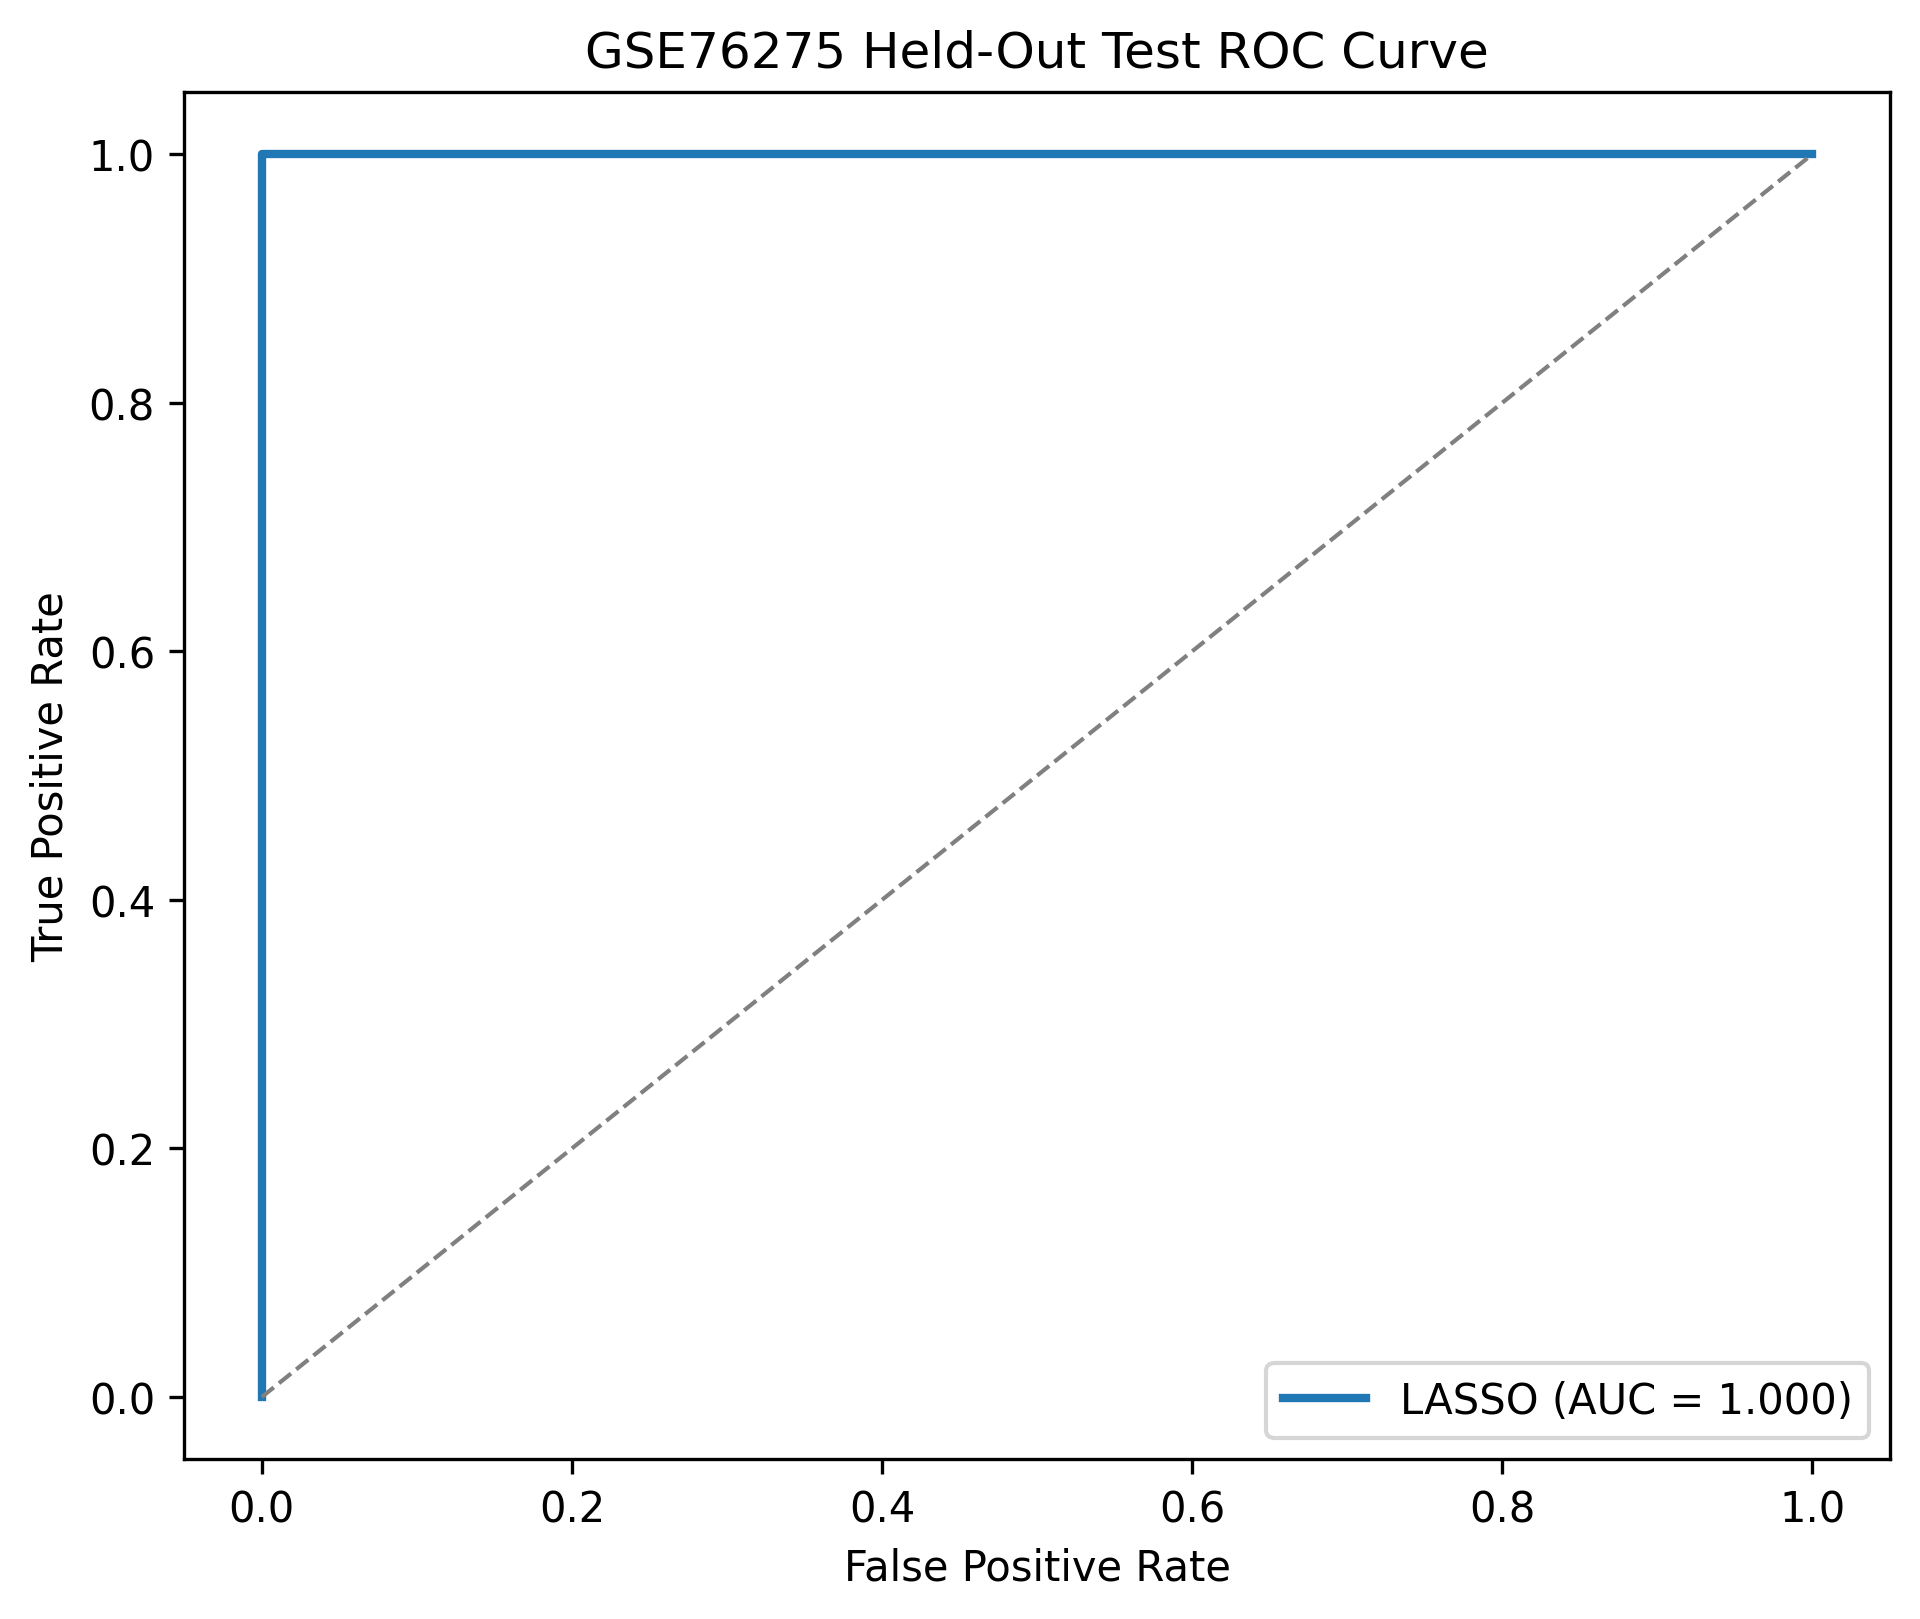

Files ready: ['roc_curve.png', 'top20_biomarkers.csv']


In [15]:
import os
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

y_prob_lasso = lasso.predict_proba(X_test)[:, 1]
y_pred_lasso = lasso.predict(X_test)
print("LASSO Test ROC-AUC:", round(roc_auc_score(y_test, y_prob_lasso), 4))
print(classification_report(y_test, y_pred_lasso, target_names=["Non-TNBC (0)", "TNBC (1)"]))

fpr, tpr, _ = roc_curve(y_test, y_prob_lasso)
plt.figure(figsize=(6.5, 5.5), dpi=300)
plt.plot(fpr, tpr, lw=2, label=f"LASSO (AUC = {roc_auc_score(y_test, y_prob_lasso):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("GSE76275 Held-Out Test ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300)
plt.show()

print("Files ready:", [f for f in ["roc_curve.png", "top20_biomarkers.csv"] if os.path.exists(f)])